# Lab 6.2 Autoencoder

In this notebook you will explore building an autoencoder with images of cranberries.

The dataset comes from the USDA: "[Images and bounding box annotations of sound and rotten cranberry fruit from a postharvest imaging platform.](https://agdatacommons.nal.usda.gov/articles/dataset/Images_and_bounding_box_annotations_of_sound_and_rotten_cranberry_fruit_from_a_postharvest_imaging_platform/31410369)" and includes images of "rotten" and "sound" cranberries, with labels.

I cropped out each cranberry into a separate image and stored them in either the "sound" or "rotten" directory, accordingly.

In [2]:
!wget -nc -q -O cranberry_dataset.zip "https://www.dropbox.com/scl/fi/sc5fkmr55yo6xzake289c/cranberry_dataset.zip?rlkey=95lfox4fuughk20cp9zxyg561&dl=1"
!unzip -n -q cranberry_dataset.zip

In [3]:
import torch
device = 'mps' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'

In [5]:
import torch
import torch.nn as nn
import torchvision
import torchmetrics
import numpy as np
from matplotlib import pyplot as plt
from tqdm import tqdm

Here we set up datasets to load the images and resize them to $32\times32$ pixels.

In [6]:
transforms = torchvision.transforms.Compose([
    torchvision.transforms.Resize((32, 32)),
    torchvision.transforms.ToTensor(),
])

train_ds_no_transform = torchvision.datasets.ImageFolder(
    'cranberry_dataset/',
)
train_ds = torchvision.datasets.ImageFolder(
    'cranberry_dataset/',
    transform=transforms
)
train_loader = torch.utils.data.DataLoader(train_ds, batch_size=32, shuffle=True)

In [7]:
train_ds

Dataset ImageFolder
    Number of datapoints: 3323
    Root location: cranberry_dataset/
    StandardTransform
Transform: Compose(
               Resize(size=(32, 32), interpolation=bilinear, max_size=None, antialias=True)
               ToTensor()
           )

Text(0.5, 1.0, 'rotten')

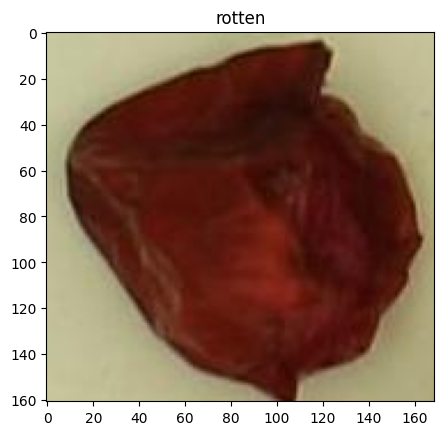

In [8]:
image,label = next(iter(train_ds_no_transform))
plt.imshow(image)
plt.title(train_ds.classes[label])

Text(0.5, 1.0, 'rotten')

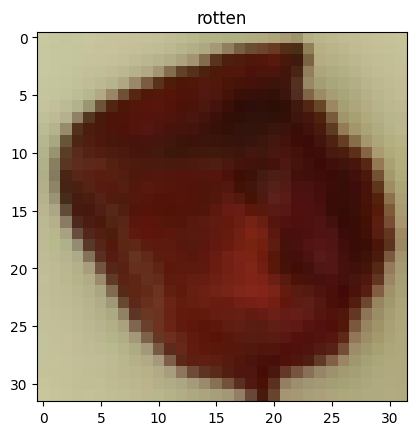

In [9]:
image,label = next(iter(train_ds))
plt.imshow(image.permute(1,2,0))
plt.title(train_ds.classes[label])

### Exercises

1. Complete this function to create separate encoder and decoder models, and then connect them in an autoencoder.

The encoder design:
- 2D convolution with kernel size 3x3, 16 output channels, stride 2, padding=1
- SiLU activation
- 2D convolution with kernel size 3x3, 32 output channels, stride 2, padding=1
- SiLU activation
- 2D convolution with kernel size 3x3, 64 output channels, stride 2, padding=1
- SiLU activation

The encoder design:
- 2D transpose convolution with kernel size 3x3, 16 output channels, stride 2, padding=1, output_padding=1
- SiLU activation
- 2D transpose convolution with kernel size 3x3, 32 output channels, stride 2, padding=1, output_padding=1
- SiLU activation
- 2D transpose convolution with kernel size 3x3, 64 output channels, stride 2, padding=1, output_padding=1
- Sigmoid activation, to make the output have range [0,1]

Connect them in a Sequential class that first runs the encoder and then the decoder -- this is the autoencoder.

Pass an image through the encoder, and then pass the encoder output through the decoder.  

What size output does the encoder have?

Verify that the output size of the decoder matches the size of the input to the encoder.


In [21]:
def make_autoencoder(device='cpu'):
    """ Make an autoencoder model with an encoder and decoder.

        Arguments:
            device: The device to use for the model. Defaults to 'cpu'.

        Returns:
            encoder: The encoder model.
            decoder: The decoder model.
            autoencoder: The autoencoder model.
    """
    # YOUR CODE GOES HERE
    encoder = nn.Sequential(
        nn.Conv2d(kernel_size=3, in_channels=3, out_channels=16, stride=2, padding=1),
        nn.SiLU(),
        nn.Conv2d(kernel_size=3, in_channels=16, out_channels=32, stride=2, padding=1),
        nn.SiLU(),
        nn.Conv2d(kernel_size=3, in_channels=32, out_channels=64, stride=2, padding=1),
        nn.SiLU()
    )

    decoder = nn.Sequential(
        nn.ConvTranspose2d(kernel_size=3, in_channels=64, out_channels=32, stride=2, padding=1, output_padding=1),
        nn.SiLU(),
        nn.ConvTranspose2d(kernel_size=3, in_channels=32, out_channels=16, stride=2, padding=1, output_padding=1),
        nn.SiLU(),
        nn.ConvTranspose2d(kernel_size=3, in_channels=16, out_channels=3, stride=2, padding=1, output_padding=1),
        nn.Sigmoid()
    )

    autoencoder = nn.Sequential(
        encoder,
        decoder
    ).to(device)
    return encoder, decoder, autoencoder

In [22]:
encoder, decoder, autoencoder = make_autoencoder(device=device)

In [23]:
image = next(iter(train_ds))[0].unsqueeze(0).to(device)
latents = encoder(image)
output = decoder(latents)
image.shape, latents.shape, output.shape

(torch.Size([1, 3, 32, 32]),
 torch.Size([1, 64, 4, 4]),
 torch.Size([1, 3, 32, 32]))

The encoder has output has 64 channels with height and width of 4. The output of the decoder has 3 channels with height and width of 32, which is the same as the encoder input size.

2. Complete this function to train the autoencoder on the dataset.

Train the autoencoder using MSE loss function (`torchmetrics.MeanSquaredError().to(device)`) and Adam optimizer with learning rate 1e-3.

I set the default number of epochs to 100, but you can reduce it (to say 30) if you don't want to wait.

In [28]:
def train_autoencoder(autoencoder, train_loader, criterion, optimizer, device='cpu', epochs=100):
    """ Train an autoencoder model.

        Arguments:
            autoencoder: The autoencoder model to train.
            train_loader: The DataLoader for the training data.
            criterion: The loss function to use.
            optimizer: The optimizer to use.
            device: The device to use for training. Defaults to 'cpu'.
            epochs: The number of epochs to train for. Defaults to 100.
    """
    autoencoder.train()
    autoencoder = autoencoder.to(device)
    # YOUR CODE GOES HERE
    for epoch in range(epochs):
        running_loss = 0
        for (X_batch, _) in train_loader:
            X_batch = X_batch.to(device)

            optimizer.zero_grad()

            z = autoencoder(X_batch)
            loss = criterion(z, X_batch)

            loss.backward()
            optimizer.step()

            running_loss += loss.item()

        if epoch % 10 == 0:
            print(f"epoch {epoch}: loss={running_loss / len(train_loader)}")

    return autoencoder


In [29]:
# YOUR CODE GOES HERE
criterion = torchmetrics.MeanSquaredError().to(device)
opt = torch.optim.Adam(autoencoder.parameters(), lr=1e-3)

autoencoder = train_autoencoder(autoencoder, train_loader, criterion, opt, device=device)

epoch 0: loss=0.037494959470887594
epoch 10: loss=0.0014621150229896347
epoch 20: loss=0.0007958480765899786
epoch 30: loss=0.0006003866664496644
epoch 40: loss=0.0004869512077465725
epoch 50: loss=0.0004180160179273046
epoch 60: loss=0.0003726351012748917
epoch 70: loss=0.00033863929694724415
epoch 80: loss=0.00032864769449448574
epoch 90: loss=0.00029869120743779396


3. This function will test the autoencoder by running some images through it.

Compare autoencoders trained with MSE and MAE loss (`torchmetrics.MeanAbsoluteError().to(device)`).  Is there any difference in sharpness?

In [34]:
def test_autoencoder(autoencoder, train_loader, device='cpu'):
    # test the autoencoder on some images
    autoencoder.eval()
    with torch.no_grad():
        test_images, _ = next(iter(train_loader))
        test_images = test_images.to(device)
        reconstructed_images = autoencoder(test_images)

    # plot the original and reconstructed images
    fig, axes = plt.subplots(2, 8, figsize=(12, 4))
    for i in range(8):

        axes[0, i].imshow(test_images[i].cpu().permute(1, 2, 0))
        axes[0, i].axis('off')
        axes[1, i].imshow(reconstructed_images[i].cpu().permute(1, 2, 0))
        axes[1, i].axis('off')
    plt.show()

In [37]:
# YOUR CODE GOES HERE
encoder_mae, decoder_mae, autoencoder_mae = make_autoencoder(device=device)
opt = torch.optim.Adam(autoencoder_mae.parameters(), lr=1e-3)
mae = torchmetrics.MeanAbsoluteError().to(device)
autoencoder_mae = train_autoencoder(autoencoder_mae, train_loader, mae, opt, device=device)

epoch 0: loss=0.16559385830679765
epoch 10: loss=0.02576044031705421
epoch 20: loss=0.020319308512485944
epoch 30: loss=0.017752963583916426
epoch 40: loss=0.01617673728077744
epoch 50: loss=0.014936756262054237
epoch 60: loss=0.014053206380385045
epoch 70: loss=0.013478160647747036
epoch 80: loss=0.012948114407033874
epoch 90: loss=0.012747674114787234


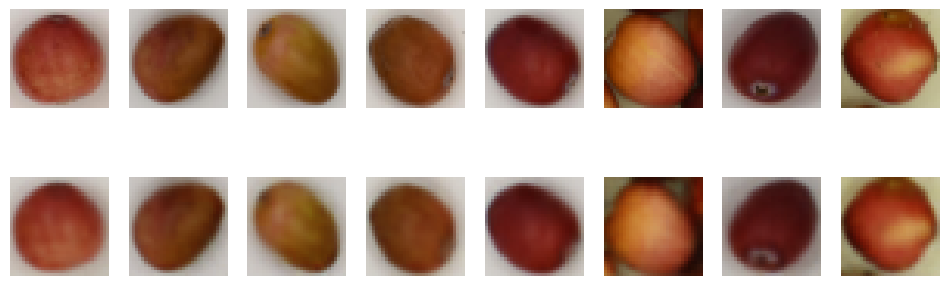

In [35]:
test_autoencoder(autoencoder, train_loader, device=device)

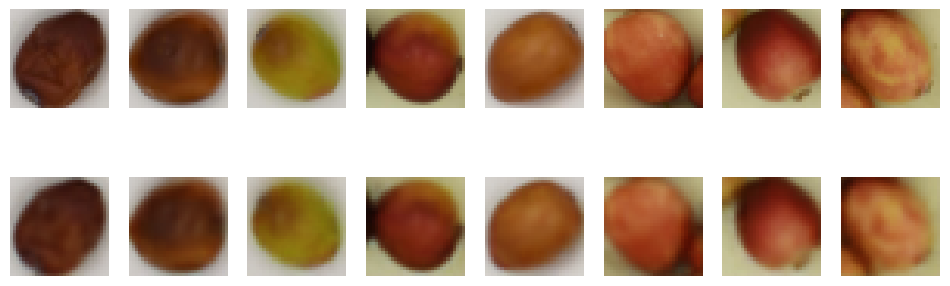

In [36]:
test_autoencoder(autoencoder_mae, train_loader, device=device)

The autoencoder trained with the mean absolute error looks a bit more blurry than the one trained with mean square error but it is hard to tell.

4. This function tests interpolating between two images.  Try it with both the MSE and MAE autoencoders and compare the results.

In [31]:
def test_interpolation(encoder, decoder, train_ds, index1=100, index2=200, device='cpu', num_steps=10):
    """ Test interpolating between two random images from the dataset.

        Arguments:
            encoder: The encoder model.
            decoder: The decoder model.
            train_ds: The dataset to sample images from.
            index1: The index of the first image in the dataset. Defaults to 100.
            index2: The index of the second image in the dataset. Defaults to 200.
            device: The device to use for computation. Defaults to 'cpu'.
            num_steps: The number of steps for interpolation. Defaults to 10.
    """
    # test interpolating between images
    with torch.no_grad():
        # Get two random images from the dataset
        img1, _ = train_ds[index1]
        img2, _ = train_ds[index2]

        # Move images to device and add batch dimension
        img1 = img1.unsqueeze(0).to(device)
        img2 = img2.unsqueeze(0).to(device)

        # Encode the images
        encoded_img1 = encoder(img1)
        encoded_img2 = encoder(img2)

        # Interpolate between the two encoded images
        interpolated_images = []
        for alpha in np.linspace(0, 1, num_steps):
            interpolated_encoded = (1 - alpha) * encoded_img1 + alpha * encoded_img2
            reconstructed_image = decoder(interpolated_encoded)
            interpolated_images.append(reconstructed_image.squeeze(0).cpu().permute(1, 2, 0))

    # Plot the interpolated images
    fig, axes = plt.subplots(1, num_steps, figsize=(15, 3))
    for i in range(num_steps):
        axes[i].imshow(interpolated_images[i])
        axes[i].axis('off')
    plt.show()

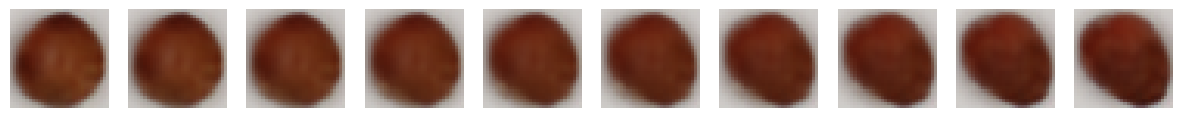

In [38]:
# YOUR CODE GOES HERE
test_interpolation(encoder, decoder, train_ds, device=device)

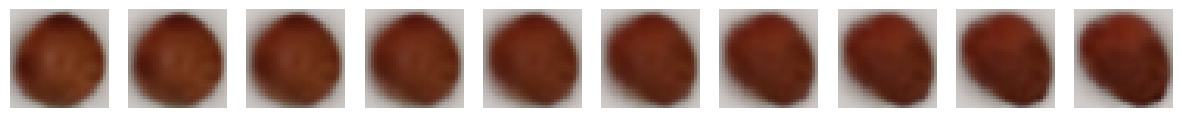

In [39]:
test_interpolation(encoder_mae, decoder_mae, train_ds, device=device)

The autoencoder with MSE look less clear than the autoencoder with MAE.